# 01 - Exploratory data analysis

**Goal of this notebook:** understand the raw data before building any model.
We check that train and test files are consistent, look at missing values, study the
four targets (`M`, `MM`, `Combo`, `DCombo`) and detect data-quality problems that the
cleaning step (notebook 02) will have to solve.

Every decision taken later in the project is justified by a finding in this notebook.

## 1. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from miopia.config import FIGURES
from miopia.data import load_raw
from miopia.plotting import BLUE, ORANGE, CLASS_COLORS, save_fig, set_style

# Display options: show all columns and round floats for readability
pd.set_option("display.max_columns", 60)
pd.set_option("display.precision", 2)
set_style()

X_train, Y_train, X_test = load_raw()
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape, "| X_test:", X_test.shape)

X_train: (132, 49) | Y_train: (132, 4) | X_test: (24, 49)


In [2]:
# Structure only: the rows are health data of real students and are never displayed
print("Feature columns:", X_train.shape[1], "| targets:", list(Y_train.columns))
for col in Y_train.columns:
    print(f"{col}: {Y_train[col].value_counts().sort_index().to_dict()}")

Feature columns: 49 | targets: ['M', 'MM', 'Combo', 'DCombo']
M: {'NO': 44, 'SI': 88}
MM: {'NO': 122, 'SI': 10}
Combo: {'C': 44, 'M': 70, 'MM': 18}
DCombo: {'C': 44, 'M1': 39, 'M2': 31, 'MM': 18}


## 2. Are train and test consistent?

Both feature files must have the same columns, in the same order and with the same types,
otherwise a model trained on one cannot be applied to the other.

In [3]:
# Same column names and order?
print("Same columns and order:", list(X_train.columns) == list(X_test.columns))

# Columns whose dtype differs between train and test
dtype_diff = pd.DataFrame({"train": X_train.dtypes, "test": X_test.dtypes})
dtype_diff[dtype_diff["train"] != dtype_diff["test"]]

Same columns and order: True


,train,test
hº ocio exteriores sem,float64,int64
hº ocio inter sem,int64,float64
Familiar miope num.,float64,int64


The column names match. Three numeric columns have a different dtype (`int64` in one file,
`float64` in the other). This is only a storage format issue: pandas reads a column as
float when it contains a decimal value or a missing value (`NaN` only exists for floats).
We cast every numeric column to `float` in both files so they have exactly the same schema.

In [4]:
num_cols = X_train.select_dtypes(include="number").columns
X_train[num_cols] = X_train[num_cols].astype(float)
X_test[num_cols] = X_test[num_cols].astype(float)

print("All dtypes match now:", (X_train.dtypes == X_test.dtypes).all())
print(f"{len(num_cols)} numeric columns, {X_train.shape[1] - len(num_cols)} text columns")

All dtypes match now: True
33 numeric columns, 16 text columns


## 3. Missing values

In [5]:
# Percentage of missing values per column, in train and test
missing = pd.DataFrame({
    "train_%": X_train.isna().mean() * 100,
    "test_%": X_test.isna().mean() * 100,
}).round(1)
missing = missing[missing.sum(axis=1) > 0].sort_values("train_%", ascending=False)
missing

,train_%,test_%
hº act.cerca sem,100.0,100.0
origen antepasados (extranjeros),74.2,75.0
Grupo fot,18.2,16.7
fototipo,15.9,16.7
Familiar miope num.,3.0,0.0
pat. Ret. Miop magna,1.5,4.2
origen antepasados (españa),1.5,4.2
hº ocio exteriores sem,1.5,0.0
horas interior sem,0.8,0.0
familiar miope,0.8,0.0


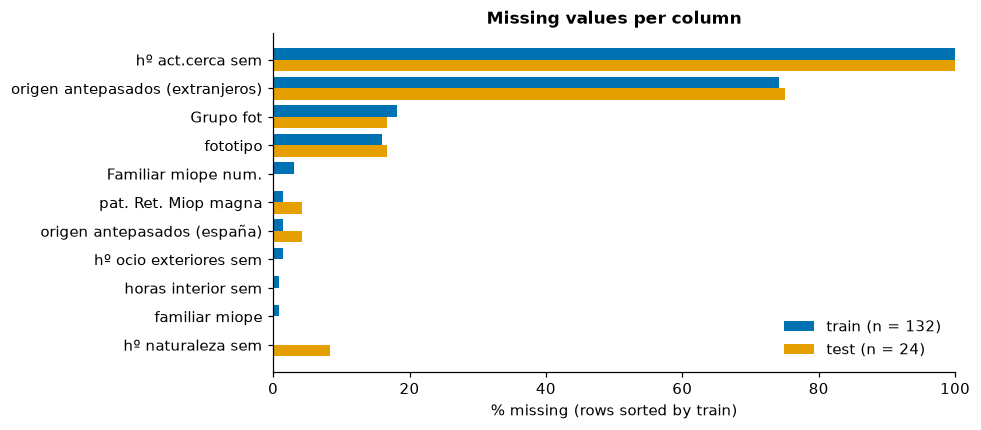

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(missing))
ax.barh(y - 0.2, missing["train_%"], height=0.4, color=BLUE, label="train (n = 132)")
ax.barh(y + 0.2, missing["test_%"], height=0.4, color=ORANGE, label="test (n = 24)")
ax.set_yticks(y, missing.index)
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("% missing (rows sorted by train)")
ax.set_title("Missing values per column")
ax.legend()
save_fig(fig, "01_missing_values")
plt.show()

- `hº act.cerca sem` is **100 % empty** in both files: it carries no information and will be dropped.
- `origen antepasados (extranjeros)` is ~75 % empty, but here a blank most likely means
  "no foreign ancestors" (some students also answered "No" explicitly, and a blank could also be a
  skipped question). Both are coded as 0 (assumption B7).
- `fototipo` is blank for a minority of students, but this table understates its real missing rate:
  many entries are not blanks but letters that belong to another column (section 5.1).
- The rest have only a few missing values (below 10 %).

## 4. Targets

The professor provides four targets. Note two differences with the brief:
labels are written `SI`/`NO` (not `YES`/`NO`), and `Combo`/`DCombo` are **multi-class**
problems (one label per student), not multi-label.

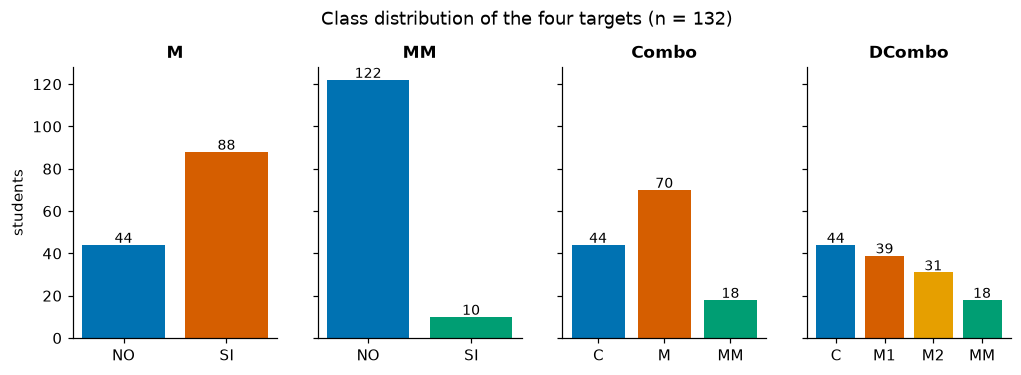

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2), sharey=True)
for ax, col in zip(axes, Y_train.columns):
    classes = list(CLASS_COLORS[col])
    counts = Y_train[col].value_counts().reindex(classes)
    ax.bar(classes, counts, color=[CLASS_COLORS[col][c] for c in classes])
    ax.set_title(col)
    for i, v in enumerate(counts):
        ax.text(i, v + 1, str(v), ha="center", fontsize=9)
axes[0].set_ylabel("students")
fig.suptitle("Class distribution of the four targets (n = 132)", y=1.04)
save_fig(fig, "01_targets")
plt.show()

In [8]:
# Accuracy of the trivial model that always predicts the most frequent class
pd.DataFrame({
    "majority class": Y_train.apply(lambda s: s.value_counts().idxmax()),
    "accuracy of always predicting it": Y_train.apply(lambda s: s.value_counts(normalize=True).max()),
})

,majority class,accuracy of always predicting it
M,SI,0.67
MM,NO,0.92
Combo,M,0.53
DCombo,C,0.33


**Class imbalance.** `MM` is the hardest task: its positive class is rare, and the table above shows
that always predicting the majority class already gives a high accuracy while detecting no case of
myopia magna. Accuracy alone therefore cannot rank models.

Plan for the validation (assumption B1, `docs/assumptions.md`):
- Models are selected with **balanced accuracy and macro-F1** under **repeated** stratified
  cross-validation. The repeats matter because a single split of 132 students holds only a handful of
  `MM` positives, so one split gives an unreliable score.
- Per-class recall is reported for every model, and accuracy is reported next to the other metrics
  because it is the metric that is graded.
- The baselines are the majority-class model and a logistic regression: a more complex model is only
  worth keeping if it clearly beats them on the selection metrics.

### 4.1 Are the four targets consistent with each other?

In [9]:
# Relationship between the targets
display(pd.crosstab(Y_train["Combo"], Y_train["MM"], margins=True))
display(pd.crosstab(Y_train["Combo"], Y_train["DCombo"]))

MM,NO,SI,All
Combo,,,
C,44,0,44
M,70,0,70
MM,8,10,18
All,122,10,132


DCombo,C,M1,M2,MM
Combo,,,,
C,44,0,0,0
M,0,39,31,0
MM,0,0,0,18


In [10]:
# Students labelled as myopia magna in Combo but NOT in the MM column (counts only, no individual rows)
inconsistent = (Y_train["Combo"] == "MM") & (Y_train["MM"] == "NO")
print("Inconsistent rows:", inconsistent.sum())
print("M among them:", Y_train.loc[inconsistent, "M"].value_counts().to_dict())
print("DCombo among them:", Y_train.loc[inconsistent, "DCombo"].value_counts().to_dict())

Inconsistent rows: 8
M among them: {'SI': 8}
DCombo among them: {'MM': 8}


**Label inconsistency found.** 8 students have `Combo = MM` but `MM = NO`.
`DCombo` agrees with `Combo` for them (`MM`), and `M` is `SI` for all of them.
The next cell compares their axial length (the main anatomical marker of myopia) with
the other groups.

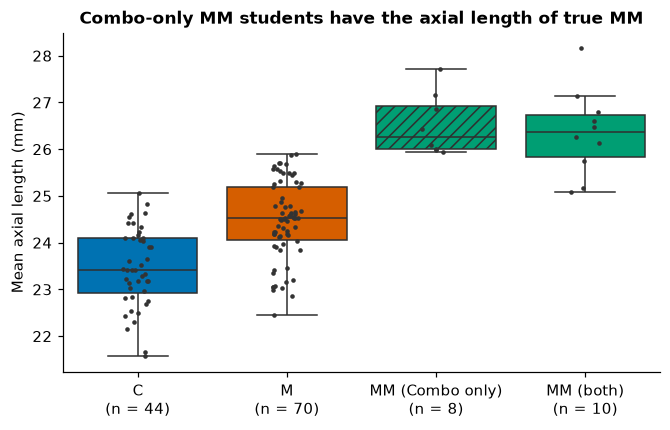

,count,median,Q1,Q3
C,44,23.42,22.93,24.10
M,70,24.52,24.06,25.20
MM (Combo only),8,26.26,26.00,26.93
MM (both),10,26.38,25.84,26.74


In [11]:
groups = pd.Series(np.select(
    [Y_train["Combo"] == "C", Y_train["Combo"] == "M", inconsistent],
    ["C", "M", "MM (Combo only)"], default="MM (both)"), index=Y_train.index)
order = ["C", "M", "MM (Combo only)", "MM (both)"]
green = CLASS_COLORS["Combo"]["MM"]
palette = {"C": CLASS_COLORS["Combo"]["C"], "M": CLASS_COLORS["Combo"]["M"],
           "MM (Combo only)": green, "MM (both)": green}

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x=groups, y=X_train["LA Media"], order=order, hue=groups, hue_order=order,
            palette=palette, saturation=1, legend=False, showfliers=False, ax=ax)
sns.stripplot(x=groups, y=X_train["LA Media"], order=order, color="0.2", size=3, ax=ax)
ax.patches[2].set_hatch("///")  # same colour as the other MM group, hatched to tell them apart
n = groups.value_counts()
ax.set_xticks(range(4), [f"{g}\n(n = {n[g]})" for g in order])
ax.set_xlabel("")
ax.set_ylabel("Mean axial length (mm)")
ax.set_title("Combo-only MM students have the axial length of true MM")
save_fig(fig, "01_inconsistent_labels")
plt.show()

g = X_train["LA Media"].groupby(groups.values)
pd.DataFrame({"count": g.size(), "median": g.median(), "Q1": g.quantile(0.25), "Q3": g.quantile(0.75)}).loc[order]

The 8 "Combo-only" students have an axial length similar to the confirmed myopia-magna
students and clearly larger than simple myopes. This suggests they are
myopia-magna cases missing from the `MM` column (or that both columns were built with
different criteria).

**Working assumption, pending confirmation by the teammate (B2, `docs/assumptions.md`):** each task is trained on its own column as
provided, because the test set is most likely graded that way. The correction of these 8 labels
is kept as an extra experiment, under three rules fixed now, before running it:
1. it is scored against the **original** `MM` labels, so both runs measure the same target;
2. the criterion for adopting the correction is written down before the experiment is run;
3. `MM = SI` is never forced just because `Combo = MM`: that pattern is valid in the training labels.

## 5. Data-quality issues in the features

### 5.1 `fototipo` and `Grupo fot`

In [12]:
pd.crosstab(X_train["fototipo"].fillna("NaN"), X_train["Grupo fot"].fillna("NaN"))

Grupo fot,E,L,NaN
fototipo,,,
E,36,0,0
Fototipo 1,9,0,0
Fototipo 2,5,0,0
Fototipo 3,31,0,0
Fototipo 4,23,0,3
Fototipo 5,2,0,0
L,0,2,0
NaN,0,0,21


`fototipo` should contain the skin phototype (1 to 5), but 38 rows contain `E` or `L`,
which are the values of `Grupo fot`. The two variables were mixed during data entry.
`Grupo fot` is almost constant (only 2 students are `L`), so it is nearly useless.
We will extract the numeric phototype (1-5) and treat `E`/`L` as missing. The next cell shows how much
this raises the missing rate.

In [13]:
# Missing rate of the phototype: blanks in the raw file vs. blanks once the letters count as missing
phototype = X_train["fototipo"].str.extract(r"(\d)")[0].astype(float)
print(f"blank in the raw file:                {X_train['fototipo'].isna().mean():.0%}")
print(f"missing once E/L count as missing:     {phototype.isna().mean():.0%}")

blank in the raw file:                16%
missing once E/L count as missing:     45%


Almost half of the students have no usable phototype, much more than the table in section 3 suggests.
Whether the feature is worth keeping is decided inside cross-validation (assumption B9), never by
looking at its association with the labels here, which would leak.

### 5.2 Exam date

In [14]:
# Exam month (day-level counts would isolate very small groups); dates are month/day/year
d = X_train["fecha"].str.extract(r"(\d{1,2})/(\d{1,2})/(\d{2})")
month = np.where(d[2] == "20", "2020-" + d[0].str.zfill(2), "year " + d[2] + " (typo)")
pd.Series(month).value_counts().sort_index()

2020-02           111
2020-03            17
year 97 (typo)      4
Name: count, dtype: int64

All exams took place in February-March 2020, except 4 rows with the year `97`, clearly a typing
error. The exam date has no causal relation with myopia, so `fecha` will be dropped.

### 5.3 Derived (redundant) columns

In [15]:
# Several columns are sums or means of others. We check it numerically.
outdoor_sum = X_train[["hº deporte sem", "hº naturaleza sem", "hº ocio exteriores sem"]].sum(axis=1)  # missing parts count as 0
checks = {
    "horas exterior = deporte + naturaleza + ocio ext.":
        np.allclose(X_train["horas exterior sem"], outdoor_sum, equal_nan=True),
    "LA Media = (LA OD + LA OS) / 2":
        np.allclose(X_train["LA Media"], (X_train["LA OD"] + X_train["LA OS"]) / 2),
    "CUVAF-Total = OD-Total + OS-Total":
        np.allclose(X_train["CUVAF-Total"], X_train["OD-Total"] + X_train["OS-Total"]),
    "Suma Nasal = 2 * Promedio Nasal":
        np.allclose(X_train["Suma Nasal"], 2 * X_train["Promedio Nasal"]),
}
pd.Series(checks, name="holds")

horas exterior = deporte + naturaleza + ocio ext.    True
LA Media = (LA OD + LA OS) / 2                       True
CUVAF-Total = OD-Total + OS-Total                    True
Suma Nasal = 2 * Promedio Nasal                      True
Name: holds, dtype: bool

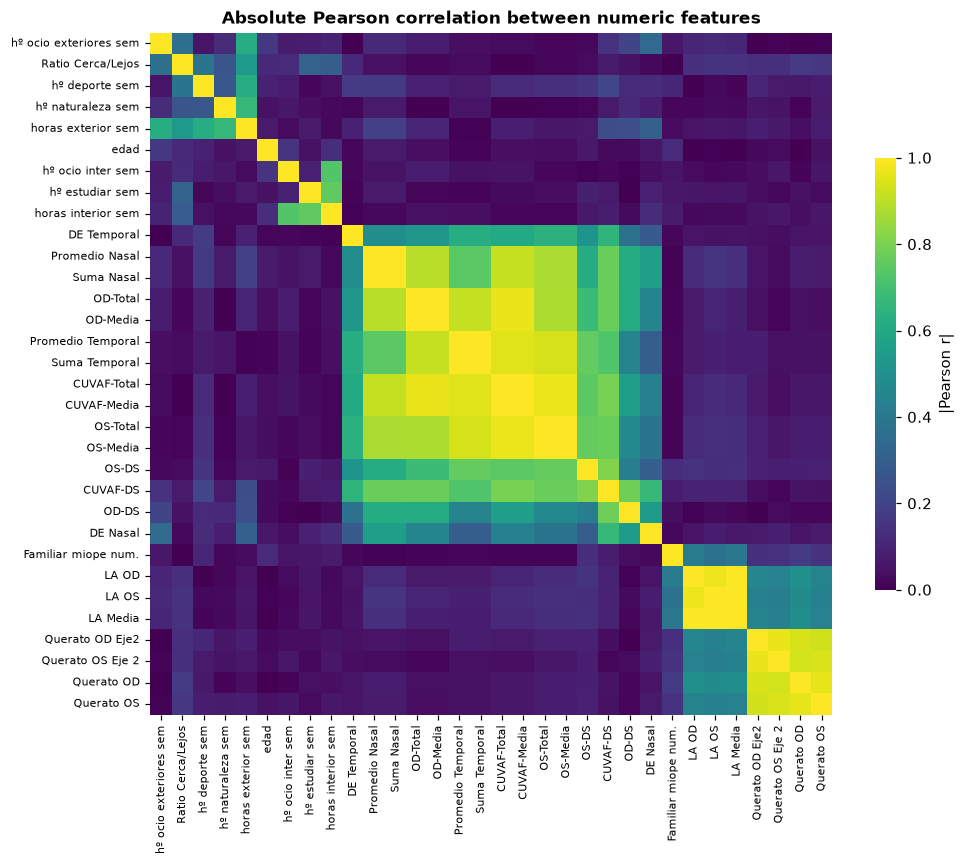

In [16]:
# Correlation between numeric features (absolute value), ordered so related columns sit together
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

corr = X_train[num_cols].drop(columns="hº act.cerca sem").corr().abs()
leaf_order = leaves_list(linkage(squareform(1 - corr.values, checks=False), "average"))
corr = corr.iloc[leaf_order, leaf_order]
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, cmap="viridis", vmin=0, vmax=1, square=True, cbar_kws={"shrink": .6, "label": "|Pearson r|"},
            xticklabels=True, yticklabels=True, ax=ax)
ax.tick_params(labelsize=7)
ax.set_title("Absolute Pearson correlation between numeric features")
save_fig(fig, "01_correlation")
plt.show()

Many features are exact combinations of others (right eye / left eye / mean / total).
Keeping all of them adds collinearity without new information, which hurts linear models
and makes feature importances hard to interpret. In feature engineering we will keep one
representative per group (e.g. the mean of both eyes).

### 5.4 Free-text and categorical columns

In [17]:
# Only the most frequent values are shown (groups of at least 10 students): rare free-text entries could identify someone
MIN_N = 10
cat_cols = X_train.columns.difference(num_cols)
def frequent(col):
    v = pd.concat([X_train[col], X_test[col]]).value_counts()
    return v[v >= MIN_N].index.tolist()[:4]

summary = pd.DataFrame({
    "n_unique": [pd.concat([X_train[c], X_test[c]]).nunique() for c in cat_cols],
    "frequent values (n >= 10)": [frequent(c) for c in cat_cols],
}, index=cat_cols).sort_values("n_unique", ascending=False)
summary

,n_unique,frequent values (n >= 10)
origen antepasados (españa),95,[Navarra]
origen antepasados (extranjeros),18,[España]
fecha,14,"[2/24/20, 2/18/20, 2/12/20, 2/11/20]"
familiar miope,10,"[No, Padre, Madre, Hermanos, Padre, Madre, Her..."
familiar miope magno,8,"[No, No lo se]"
fototipo,7,"[E, Fototipo 3, Fototipo 4, Fototipo 1]"
disp.elec.antes dormir,3,"[Siempre, A veces]"
Familiar MM SI/NO,3,"[No, No lo se, Si]"
pat. Ret. Miop magna,3,"[No, No lo se]"
Grupo fot,2,[E]


- `origen antepasados (españa)` has 95 different free-text values for 156 students: too
  sparse to be used directly (and the text would need normalising before the count means much),
  so it is dropped.
- `origen antepasados (extranjeros)` is also free text, but a derived flag (has foreign ancestors
  yes/no) built from **this** column is usable.
- `familiar miope` lists which relatives are myopic (father, mother, siblings). It can be
  turned into binary columns (`father_myopic`, `mother_myopic`, `siblings_myopic`).
- The remaining columns are small yes/no or ordinal categories (`Nunca` < `A veces` < `Siempre`).

## 6. Which features are related to myopia?

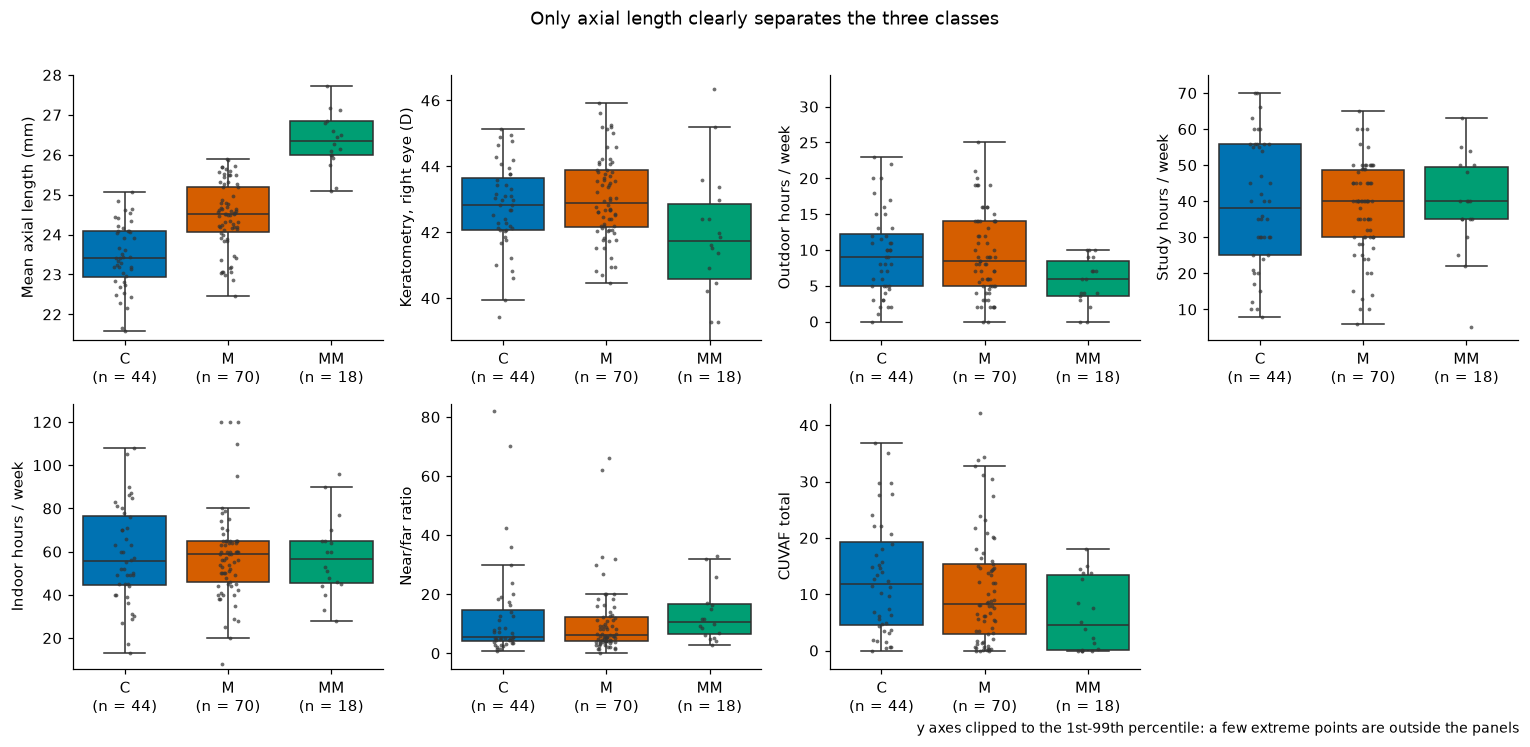

In [18]:
# Distribution of the main numeric features by class (y axis clipped to the 1st-99th percentile so single outliers do not squash the boxes; age is left out because it is whole years and the boxes collapse)
key_vars = {"LA Media": "Mean axial length (mm)", "Querato OD": "Keratometry, right eye (D)",
            "horas exterior sem": "Outdoor hours / week", "hº estudiar sem": "Study hours / week",
            "horas interior sem": "Indoor hours / week", "Ratio Cerca/Lejos": "Near/far ratio",
            "CUVAF-Total": "CUVAF total"}
df = X_train.join(Y_train)
classes = ["C", "M", "MM"]
n_class = df["Combo"].value_counts()

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
axes.ravel()[-1].set_visible(False)
for ax, (var, label) in zip(axes.ravel(), key_vars.items()):
    sns.boxplot(data=df, x="Combo", y=var, order=classes, hue="Combo", hue_order=classes,
                palette=CLASS_COLORS["Combo"], saturation=1, legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=df, x="Combo", y=var, order=classes, color="0.2", size=2.5, alpha=0.7, ax=ax)
    lo, hi = df[var].quantile([0.01, 0.99])
    pad = 0.08 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xticks(range(3), [f"{c}\n(n = {n_class[c]})" for c in classes])
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.tick_params(labelsize=10)
fig.suptitle("Only axial length clearly separates the three classes", y=1.01)
fig.text(0.99, 0.0, "y axes clipped to the 1st-99th percentile: a few extreme points are outside the panels",
         ha="right", fontsize=9)
fig.tight_layout()
save_fig(fig, "01_numeric_by_class")
plt.show()

In [19]:
# Non-parametric test (Kruskal-Wallis) to rank numeric features by how well they separate C / M / MM.
# 32 features are tested, so a Bonferroni-corrected p-value (p x 32, capped at 1) is shown next to the raw one.
from scipy.stats import kruskal

rows = []
for var in num_cols.drop("hº act.cerca sem"):
    samples = [df.loc[df["Combo"] == g, var].dropna() for g in ["C", "M", "MM"]]
    stat, p = kruskal(*samples)
    rows.append((var, stat, p))
ranking = pd.DataFrame(rows, columns=["feature", "H", "p_value"]).sort_values("p_value")
ranking["p_corrected"] = (ranking["p_value"] * len(ranking)).clip(upper=1)
display(ranking.head(8).style.format({"H": "{:.1f}", "p_value": "{:.1e}", "p_corrected": "{:.3f}"}))
print("Mean axial length (mm) by Combo class:")
print(df.groupby("Combo")["LA Media"].mean().round(1).to_dict())

,feature,H,p_value,p_corrected
11,LA OS,65.8,5.1e-15,0.000
12,LA Media,64.7,8.9e-15,0.000
10,LA OD,63.0,2.1e-14,0.000
9,Familiar miope num.,16.5,2.6e-04,0.008
1,hº deporte sem,12.9,1.6e-03,0.051
21,OS-Media,8.8,1.2e-02,0.390
20,OS-Total,8.8,1.2e-02,0.390
13,Querato OD,8.4,1.5e-02,0.481


Mean axial length (mm) by Combo class:
{'C': 23.5, 'M': 24.5, 'MM': 26.4}


Axial length (`LA`) is by far the strongest predictor and stays significant after the correction for
testing many features: it grows from controls to myopia and again to myopia magna. This is consistent
with the medical literature: myopia is associated with an elongated eyeball.

Among the other features only the number of myopic parents stands out after the correction (notebook 02 shows that this column
is just father plus mother and handles it there). The weekly hours of sport
look related to the class when tested alone, but the evidence is borderline after the correction, so
we treat it as a weak hint at most and let cross-validation decide whether the feature helps.

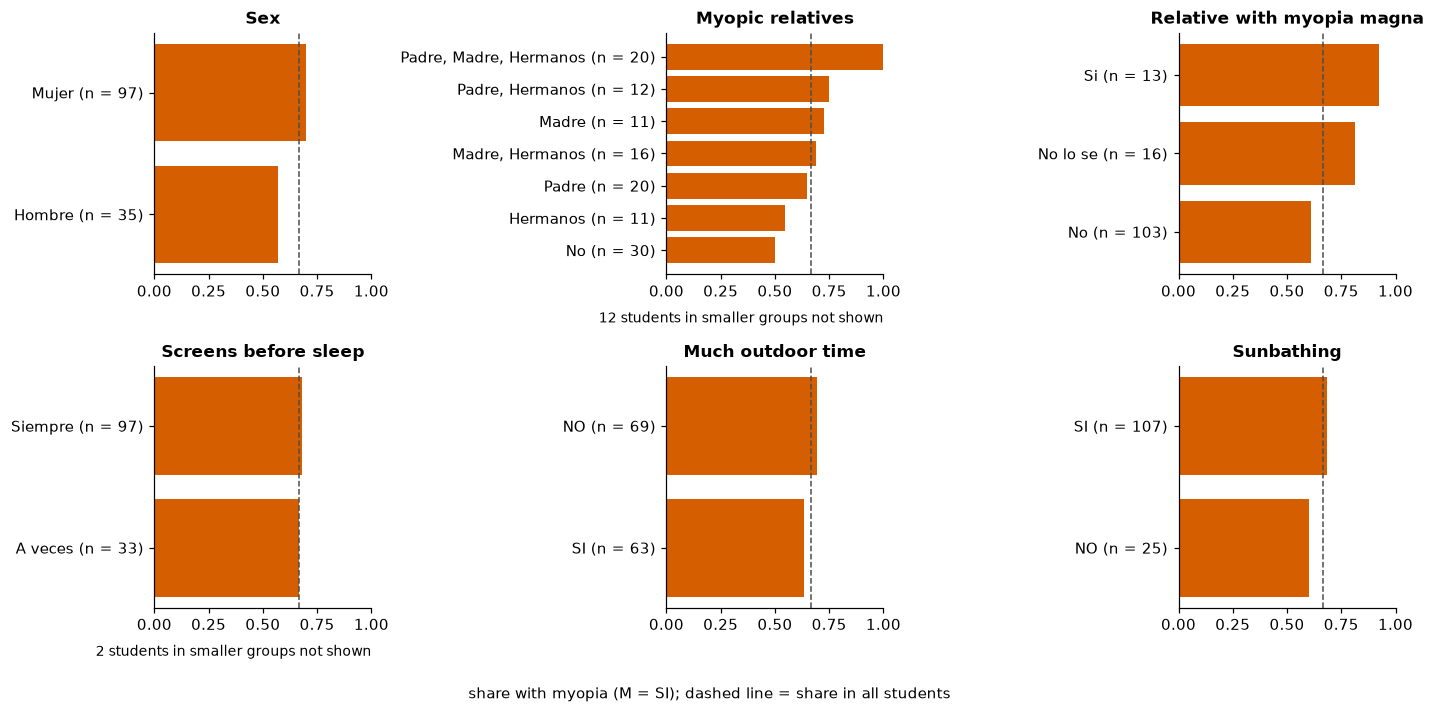

In [20]:
# Proportion of myopic students for each value of some categorical features.
# Groups with fewer than 10 students are left out: a bar for a handful of people (or one) is not
# reliable and could point at an individual. The dashed line is the overall share of myopic students.
MIN_N = 10
cat_vars = {"sexo": "Sex", "familiar miope": "Myopic relatives", "Familiar MM SI/NO": "Relative with myopia magna",
            "disp.elec.antes dormir": "Screens before sleep", "Exterior Mucho": "Much outdoor time", "toma sol": "Sunbathing"}
base_rate = (df["M"] == "SI").mean()
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (var, title) in zip(axes.ravel(), cat_vars.items()):
    n = df[var].value_counts()
    keep = n[n >= MIN_N].index
    prop = (df.loc[df[var].isin(keep)].groupby(var)["M"].apply(lambda s: (s == "SI").mean())
            .sort_values())
    ax.barh([f"{k} (n = {n[k]})" for k in prop.index], prop.values, color=CLASS_COLORS["M"]["SI"])
    ax.axvline(base_rate, color="0.3", linestyle="--", linewidth=1)
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.tick_params(labelsize=10)
    hidden = len(df) - n[keep].sum()
    if hidden:
        ax.text(1, -0.2, f"{hidden} students in smaller groups not shown", transform=ax.transAxes,
                ha="right", fontsize=9)
fig.supxlabel("share with myopia (M = SI); dashed line = share in all students", fontsize=10)
fig.tight_layout()
save_fig(fig, "01_categorical_vs_M")
plt.show()

## 7. Do train and test come from the same distribution?

If the test students were very different from the training students, the validation score
would be an optimistic estimate of the test score.

In [21]:
from scipy.stats import ks_2samp

# Kolmogorov-Smirnov test on each numeric column (small p-value = different distributions)
shift = []
for var in num_cols.drop("hº act.cerca sem"):
    stat, p = ks_2samp(X_train[var].dropna(), X_test[var].dropna())
    shift.append((var, round(stat, 2), round(p, 3)))
shift = pd.DataFrame(shift, columns=["feature", "KS", "p_value"]).sort_values("p_value")
shift.head(8)

,feature,KS,p_value
9,Familiar miope num.,0.29,0.06
27,DE Nasal,0.23,0.20
7,horas interior sem,0.23,0.21
3,hº ocio exteriores sem,0.21,0.27
5,hº estudiar sem,0.21,0.28
2,hº naturaleza sem,0.22,0.29
16,Querato OS Eje 2,0.19,0.39
25,CUVAF-DS,0.19,0.39


With only 24 test students the test has little power, but no numeric feature shows a strong shift.
This is no evidence of a difference between train and test (low power, numeric columns only), so we
work as if both come from the same population (assumption B4).

## 8. Summary of findings and decisions for notebook 02

| # | Finding | Action |
|---|---|---|
| 1 | Same columns; 3 numeric columns with different dtype (int/float) | Cast all numeric columns to float |
| 2 | `hº act.cerca sem` 100 % empty | Drop |
| 3 | `fecha` irrelevant and with typos | Drop |
| 4 | `fototipo` mixed with `Grupo fot` values (`E`, `L`): almost half of the students end up without a phototype | Keep numeric phototype 1-5, `E`/`L` → missing; keep or drop is decided inside CV (B9) |
| 5 | `Grupo fot` almost constant | Drop |
| 6 | Many redundant columns (eye OD/OS/mean/total, outdoor sum) | Keep one representative per group |
| 7 | Free-text ancestry; the `extranjeros` column holds the foreign ancestors | Binary flag "foreign ancestors" from `extranjeros`; drop the `españa` text |
| 8 | `familiar miope` lists relatives | One binary column per relative |
| 9 | 8 rows with `Combo = MM` but `MM = NO` | Train each task on its own column; correction as an extra experiment under the three rules of B2 |
| 10 | Strong imbalance (`MM`: 10 / 132) | Repeated stratified CV; select on balanced accuracy and macro-F1 (B1), report accuracy and per-class recall; majority class and logistic regression as baselines |
| 11 | Axial length is the dominant predictor | Expect it at the top of feature importances |
| 12 | Sport hours are not significant once 32 features are tested together | No special treatment; CV decides |